# SmartCar – Used Car Price Prediction
## Google Colab Notebook (Cell-by-Cell)

**Goal:** Train and evaluate machine-learning regression models to estimate used-car selling prices from the CarDekho dataset.

### Dataset
This notebook is prepared for the ZIP file containing:
- `CAR DETAILS FROM CAR DEKHO.csv`
- `Car details v3.csv`
- `car data.csv`
- `car details v4.csv`

We use **`Car details v3.csv`** by default because it contains useful vehicle features such as mileage, engine capacity, power, and seats.

**Target:** `selling_price` (Indian Rupees)

> Run the cells from top to bottom. Upload your dataset ZIP when prompted.

## Cell 1 — Import libraries

In [1]:
import os
import zipfile
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

print("Libraries imported successfully.")

Libraries imported successfully.


## Cell 2 — Upload the dataset ZIP file

In [2]:
from google.colab import files

uploaded = files.upload()  # Select archive (3).zip or your CarDekho dataset ZIP
zip_filename = next(iter(uploaded.keys()))
print("Uploaded file:", zip_filename)

Saving archive (3).zip to archive (3).zip
Uploaded file: archive (3).zip


## Cell 3 — Extract the ZIP file

In [3]:
extract_dir = "/content/cardekho_dataset"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

csv_files = glob.glob(os.path.join(extract_dir, "*.csv"))
print("CSV files found:")
for file_path in csv_files:
    print("-", os.path.basename(file_path))

CSV files found:
- CAR DETAILS FROM CAR DEKHO.csv
- car details v4.csv
- car data.csv
- Car details v3.csv


## Cell 4 — Load Car details v3.csv

In [4]:
preferred_file = os.path.join(extract_dir, "Car details v3.csv")

if os.path.exists(preferred_file):
    dataset_path = preferred_file
else:
    # Fallback: load the first CSV found if the preferred filename is not present
    dataset_path = csv_files[0]

df = pd.read_csv(dataset_path)
print("Loaded:", os.path.basename(dataset_path))
print("Dataset shape:", df.shape)
df.head()

Loaded: Car details v3.csv
Dataset shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


## Cell 5 — Understand the dataset

In [5]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nStatistical summary:")
display(df.describe(include="all").T)

Rows and columns: (8128, 13)
\nColumn names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Cell 6 — Check missing values and duplicates

In [6]:
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())

Missing values per column:


,0
torque,222
seats,221
engine,221
mileage,221
max_power,215
fuel,0
km_driven,0
selling_price,0
year,0
name,0


Duplicate rows: 1202


## Cell 7 — Clean column names

In [7]:
# Convert column names to lowercase and replace spaces with underscores
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print(df.columns.tolist())

['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']


## Cell 8 — Clean and convert numeric feature columns

The dataset stores mileage, engine and max power with text units (for example, `23.4 kmpl`, `1248 CC`, `74 bhp`). We extract the numeric part so the model can use them.

In [8]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert text-with-units columns to numeric values
numeric_text_columns = ["mileage", "engine", "max_power", "seats"]

for col in numeric_text_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.extract(r"([-+]?[0-9]*\\.?[0-9]+)", expand=False),
            errors="coerce"
        )

# Ensure target and core numeric columns are numeric
for col in ["selling_price", "year", "km_driven"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows where the target price is missing or not positive
df = df.dropna(subset=["selling_price"])
df = df[df["selling_price"] > 0].copy()

print("Cleaned dataset shape:", df.shape)
display(df.head())

Cleaned dataset shape: (6926, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,190Nm@ 2000rpm,NaN
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,250Nm@ 1500-2500rpm,NaN
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,NaN,NaN,NaN,"12.7@ 2,700(kgm@ rpm)",NaN
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,22.4 kgm at 1750-2750rpm,NaN
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,NaN,NaN,NaN,"11.5@ 4,500(kgm@ rpm)",NaN


## Cell 9 — Exploratory Data Analysis (EDA): target price distribution

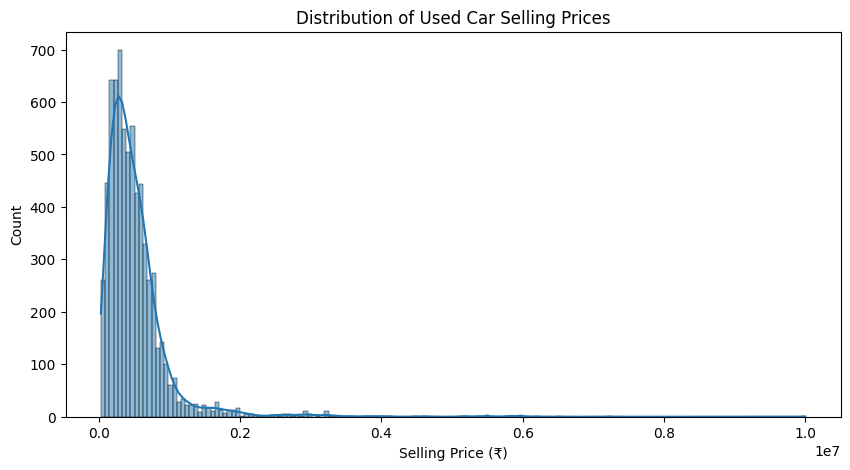

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(df["selling_price"], kde=True)
plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Count")
plt.show()

## Cell 10 — Analyze price by fuel type

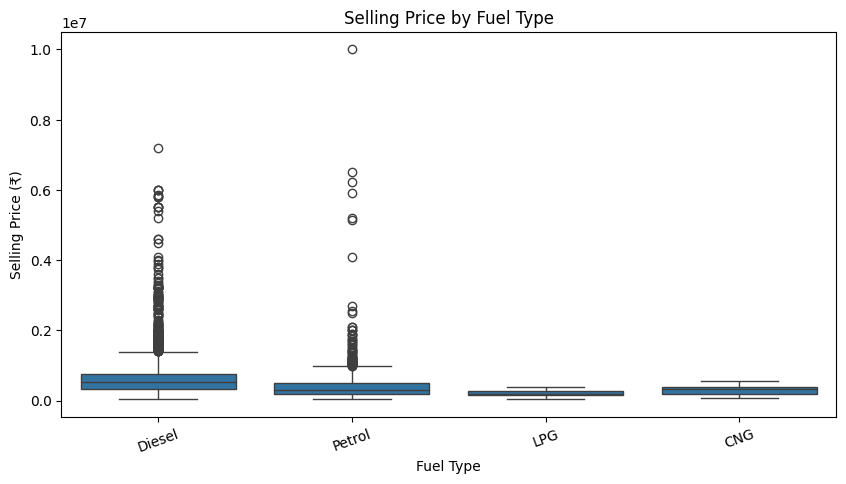

In [10]:
if "fuel" in df.columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x="fuel", y="selling_price")
    plt.title("Selling Price by Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Selling Price (₹)")
    plt.xticks(rotation=20)
    plt.show()
else:
    print("Fuel column not available in this selected CSV.")

## Cell 11 — Feature engineering

In [11]:
# Create car age from the manufacturing year.
# Using a fixed reference year makes results reproducible.
REFERENCE_YEAR = 2026

if "year" in df.columns:
    df["car_age"] = (REFERENCE_YEAR - df["year"]).clip(lower=0)

# Drop columns that are not used as model inputs
# `name` is retained because model/variant can strongly affect price.
drop_columns = ["selling_price"]
X = df.drop(columns=drop_columns)
y = df["selling_price"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Feature matrix shape: (6926, 13)
Target shape: (6926,)


,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,car_age
0,Maruti Swift Dzire VDI,2014,145500,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,190Nm@ 2000rpm,NaN,12
1,Skoda Rapid 1.5 TDI Ambition,2014,120000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,250Nm@ 1500-2500rpm,NaN,12
2,Honda City 2017-2020 EXi,2006,140000,Petrol,Individual,Manual,Third Owner,NaN,NaN,NaN,"12.7@ 2,700(kgm@ rpm)",NaN,20
3,Hyundai i20 Sportz Diesel,2010,127000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,22.4 kgm at 1750-2750rpm,NaN,16
4,Maruti Swift VXI BSIII,2007,120000,Petrol,Individual,Manual,First Owner,NaN,NaN,NaN,"11.5@ 4,500(kgm@ rpm)",NaN,19


## Cell 12 — Define numeric and categorical features

In [12]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'car_age']
Categorical features: ['name', 'fuel', 'seller_type', 'transmission', 'owner', 'torque']


## Cell 13 — Split into training and testing datasets

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 5540
Testing rows: 1386


## Cell 14 — Build preprocessing pipeline

- Numeric columns: median imputation and scaling
- Categorical columns: most-frequent imputation and one-hot encoding
- `handle_unknown="ignore"` allows the model to handle categories not seen during training.

In [14]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## Cell 15 — Train and compare ML models

In [15]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []
trained_pipelines = {}

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE (₹)": mae,
        "RMSE (₹)": rmse,
        "R2 Score": r2
    })

    trained_pipelines[model_name] = pipeline

results_df = pd.DataFrame(results).sort_values(by="MAE (₹)")
display(results_df)

,Model,MAE (₹),RMSE (₹),R2 Score
0,Linear Regression,95266.716710,255037.314897,0.703431
2,Random Forest,105127.111513,251826.522978,0.710851
1,Decision Tree,107289.409692,280816.223958,0.640447
3,Gradient Boosting,142846.717565,284382.795066,0.631256


## Cell 16 — Visualize model comparison

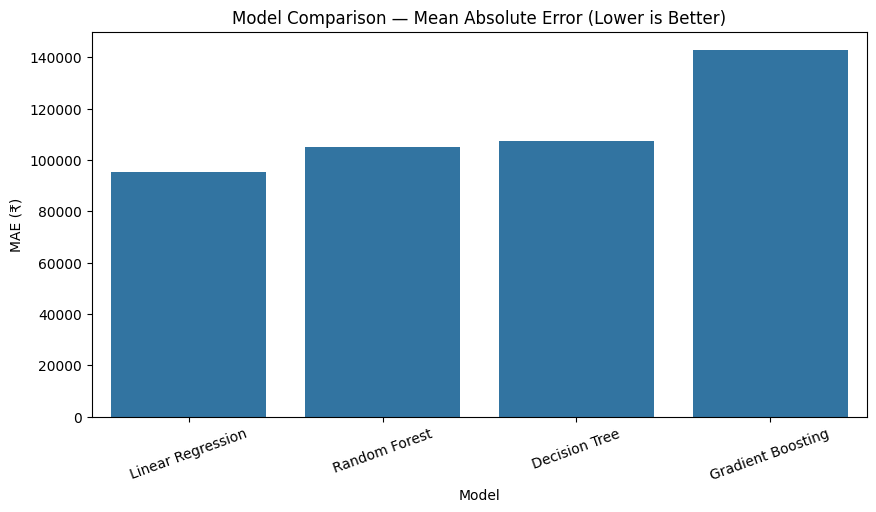

In [16]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="MAE (₹)")
plt.title("Model Comparison — Mean Absolute Error (Lower is Better)")
plt.ylabel("MAE (₹)")
plt.xticks(rotation=20)
plt.show()

## Cell 17 — Select the best model

In [17]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_pipelines[best_model_name]

print("Best model based on lowest MAE:", best_model_name)
print("MAE:", round(results_df.iloc[0]["MAE (₹)"], 2), "₹")
print("RMSE:", round(results_df.iloc[0]["RMSE (₹)"], 2), "₹")
print("R² Score:", round(results_df.iloc[0]["R2 Score"], 4))

Best model based on lowest MAE: Linear Regression
MAE: 95266.72 ₹
RMSE: 255037.31 ₹
R² Score: 0.7034


## Cell 18 — Check predictions against actual prices

In [18]:
sample_predictions = best_model.predict(X_test)

comparison_df = pd.DataFrame({
    "Actual Price (₹)": y_test.values,
    "Predicted Price (₹)": sample_predictions,
    "Absolute Error (₹)": np.abs(y_test.values - sample_predictions)
})

display(comparison_df.head(15))

,Actual Price (₹),Predicted Price (₹),Absolute Error (₹)
0,550000,5.987681e+05,48768.149669
1,1225000,1.198285e+06,26715.419394
2,850000,8.579991e+05,7999.148911
3,80000,1.513362e+05,71336.205598
4,825000,6.200075e+05,204992.545604
5,800000,9.359722e+05,135972.183503
6,229999,2.836374e+05,53638.410335
7,93150,1.886536e+05,95503.613890
8,300000,2.677269e+05,32273.069471
9,493000,4.806173e+05,12382.741618


## Cell 19 — Plot actual vs predicted prices

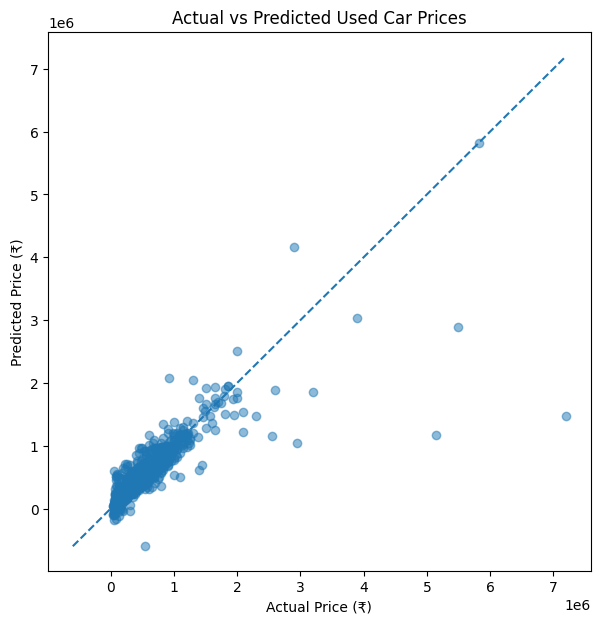

In [19]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, sample_predictions, alpha=0.5)
min_value = min(y_test.min(), sample_predictions.min())
max_value = max(y_test.max(), sample_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title("Actual vs Predicted Used Car Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.show()

## Cell 20 — Predict the price of a sample car

In [20]:
# Create a sample using the first row of the feature dataset.
# Replace values with details of a car you want to estimate.
sample_car = X.iloc[[0]].copy()

predicted_price = best_model.predict(sample_car)[0]
print("Sample car details:")
display(sample_car)
print(f"Estimated selling price: ₹{predicted_price:,.0f}")

Sample car details:


,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,car_age
0,Maruti Swift Dzire VDI,2014,145500,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,190Nm@ 2000rpm,NaN,12


Estimated selling price: ₹511,800


## Cell 21 — Save the trained model

In [21]:
import joblib

model_filename = "smartcar_best_model.joblib"
joblib.dump(best_model, model_filename)

print("Saved model:", model_filename)

Saved model: smartcar_best_model.joblib


## Cell 22 — Download the trained model

In [22]:
from google.colab import files
files.download("smartcar_best_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next steps

After completing model training:
1. Build a FastAPI endpoint that loads `smartcar_best_model.joblib`.
2. Build a React.js form for entering car features.
3. Connect React to FastAPI and show the estimated price.
4. Add prediction history storage using MongoDB.

**Important:** The estimate is based on patterns in this dataset. It is not a guaranteed market valuation. Evaluate errors across different car types and price ranges before presenting it as a real-world service.